# Core vs MTG LI over Western Sahel JJAS

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

In [2]:
base = "/work/scratch-nopw2/mendrika/ASNIE/final-database/LI/parquet"

core_thresholds = [40.0]
li_thresholds = [0.0, 0.032, 1.056] #0, 50, and 90th percentile

cores = {}
lis = {}

for thr in core_thresholds:

    tag = f"thr_{thr}".replace(".", "p")

    cores[thr] = pd.read_parquet(
        f"{base}/core_{tag}.parquet"
    )

for thr in li_thresholds:

    tag = f"thr_{thr}".replace(".", "p")

    lis[thr] = pd.read_parquet(
        f"{base}/li_{tag}.parquet"
    )

In [3]:
print("core:", cores[40.0]["time"].min(), cores[40.0]["time"].max())

for thr in li_thresholds:
    print("li", thr, lis[thr]["time"].min(), lis[thr]["time"].max())

core: 2025-06-01 00:15:00 2025-08-31 09:00:00
li 0.0 2025-06-01 00:15:00 2025-08-31 09:00:00
li 0.032 2025-06-01 00:15:00 2025-08-31 09:00:00
li 1.056 2025-06-01 00:15:00 2025-08-31 09:00:00


In [4]:
def latlon_to_xy_km(lat, lon):
    """
    Convert latitude and longitude coordinates to approximate Cartesian
    coordinates in kilometres.

    This function applies a simple equirectangular projection to transform
    geographic coordinates (lat, lon) into planar (x, y) coordinates. The
    conversion is suitable for computing Euclidean distances between nearby
    points (e.g., storm-object centroids) over a limited geographic region.

    Longitude distances are scaled by cos(mean latitude) to account for the
    decrease in east–west distance away from the equator.

    Parameters
    ----------
    lat : array-like
        Latitudes in degrees.
    lon : array-like
        Longitudes in degrees.

    Returns
    -------
    xy : ndarray of shape (N, 2)
        Array containing projected coordinates in kilometres, where each row
        corresponds to a point (x, y).
    """

    R = 6371.0

    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)

    x = R * lon_rad * np.cos(np.mean(lat_rad))                      # mean to make sure it's consistent across dataset (assuming a single reference latitude for simplicity)
    y = R * lat_rad

    return np.column_stack((x, y))

In [5]:
def core_to_li_distances(df_core, df_li):
    """
    Compute the distance from each core object to the nearest lightning object
    at the same timestep.

    The function groups core objects by their timestamp, selects lightning
    objects occurring at the same time, converts their geographic coordinates
    to approximate Cartesian coordinates (km), and uses a KD-tree to efficiently
    find the nearest lightning object for each core.

    Parameters
    ----------
    df_core : pandas.DataFrame
        DataFrame containing core objects with centroid coordinates and a
        'time' column.
    df_li : pandas.DataFrame
        DataFrame containing lightning objects with centroid coordinates and
        a 'time' column.

    Returns
    -------
    numpy.ndarray
        Array of nearest-neighbour distances (km) from each core to the closest
        lightning object at the same time.
    """

    matches = []

    # Process objects timestep by timestep
    for t, core_group in df_core.groupby("time"):

        # Select lightning objects at the same time
        li_group = df_li[df_li["time"] == t]

        if len(core_group) == 0 or len(li_group) == 0:
            continue

        # Convert lightning centroids to Cartesian km coordinates
        li_xy = latlon_to_xy_km(
            li_group["lat_centroid"].values,
            li_group["lon_centroid"].values
        )

        # Build KD-tree for fast nearest-neighbour search
        tree = cKDTree(li_xy)

        # Convert core centroids to Cartesian km coordinates
        core_xy = latlon_to_xy_km(
            core_group["lat_centroid"].values,
            core_group["lon_centroid"].values
        )

        # Distance from each core to nearest lightning object
        distances, _ = tree.query(core_xy, k=1)

        matches.extend(distances)

    return np.array(matches)

In [6]:
distances = {}

for thr, li_df in lis.items():

    distances[thr] = core_to_li_distances(
        cores[40],
        li_df
    )

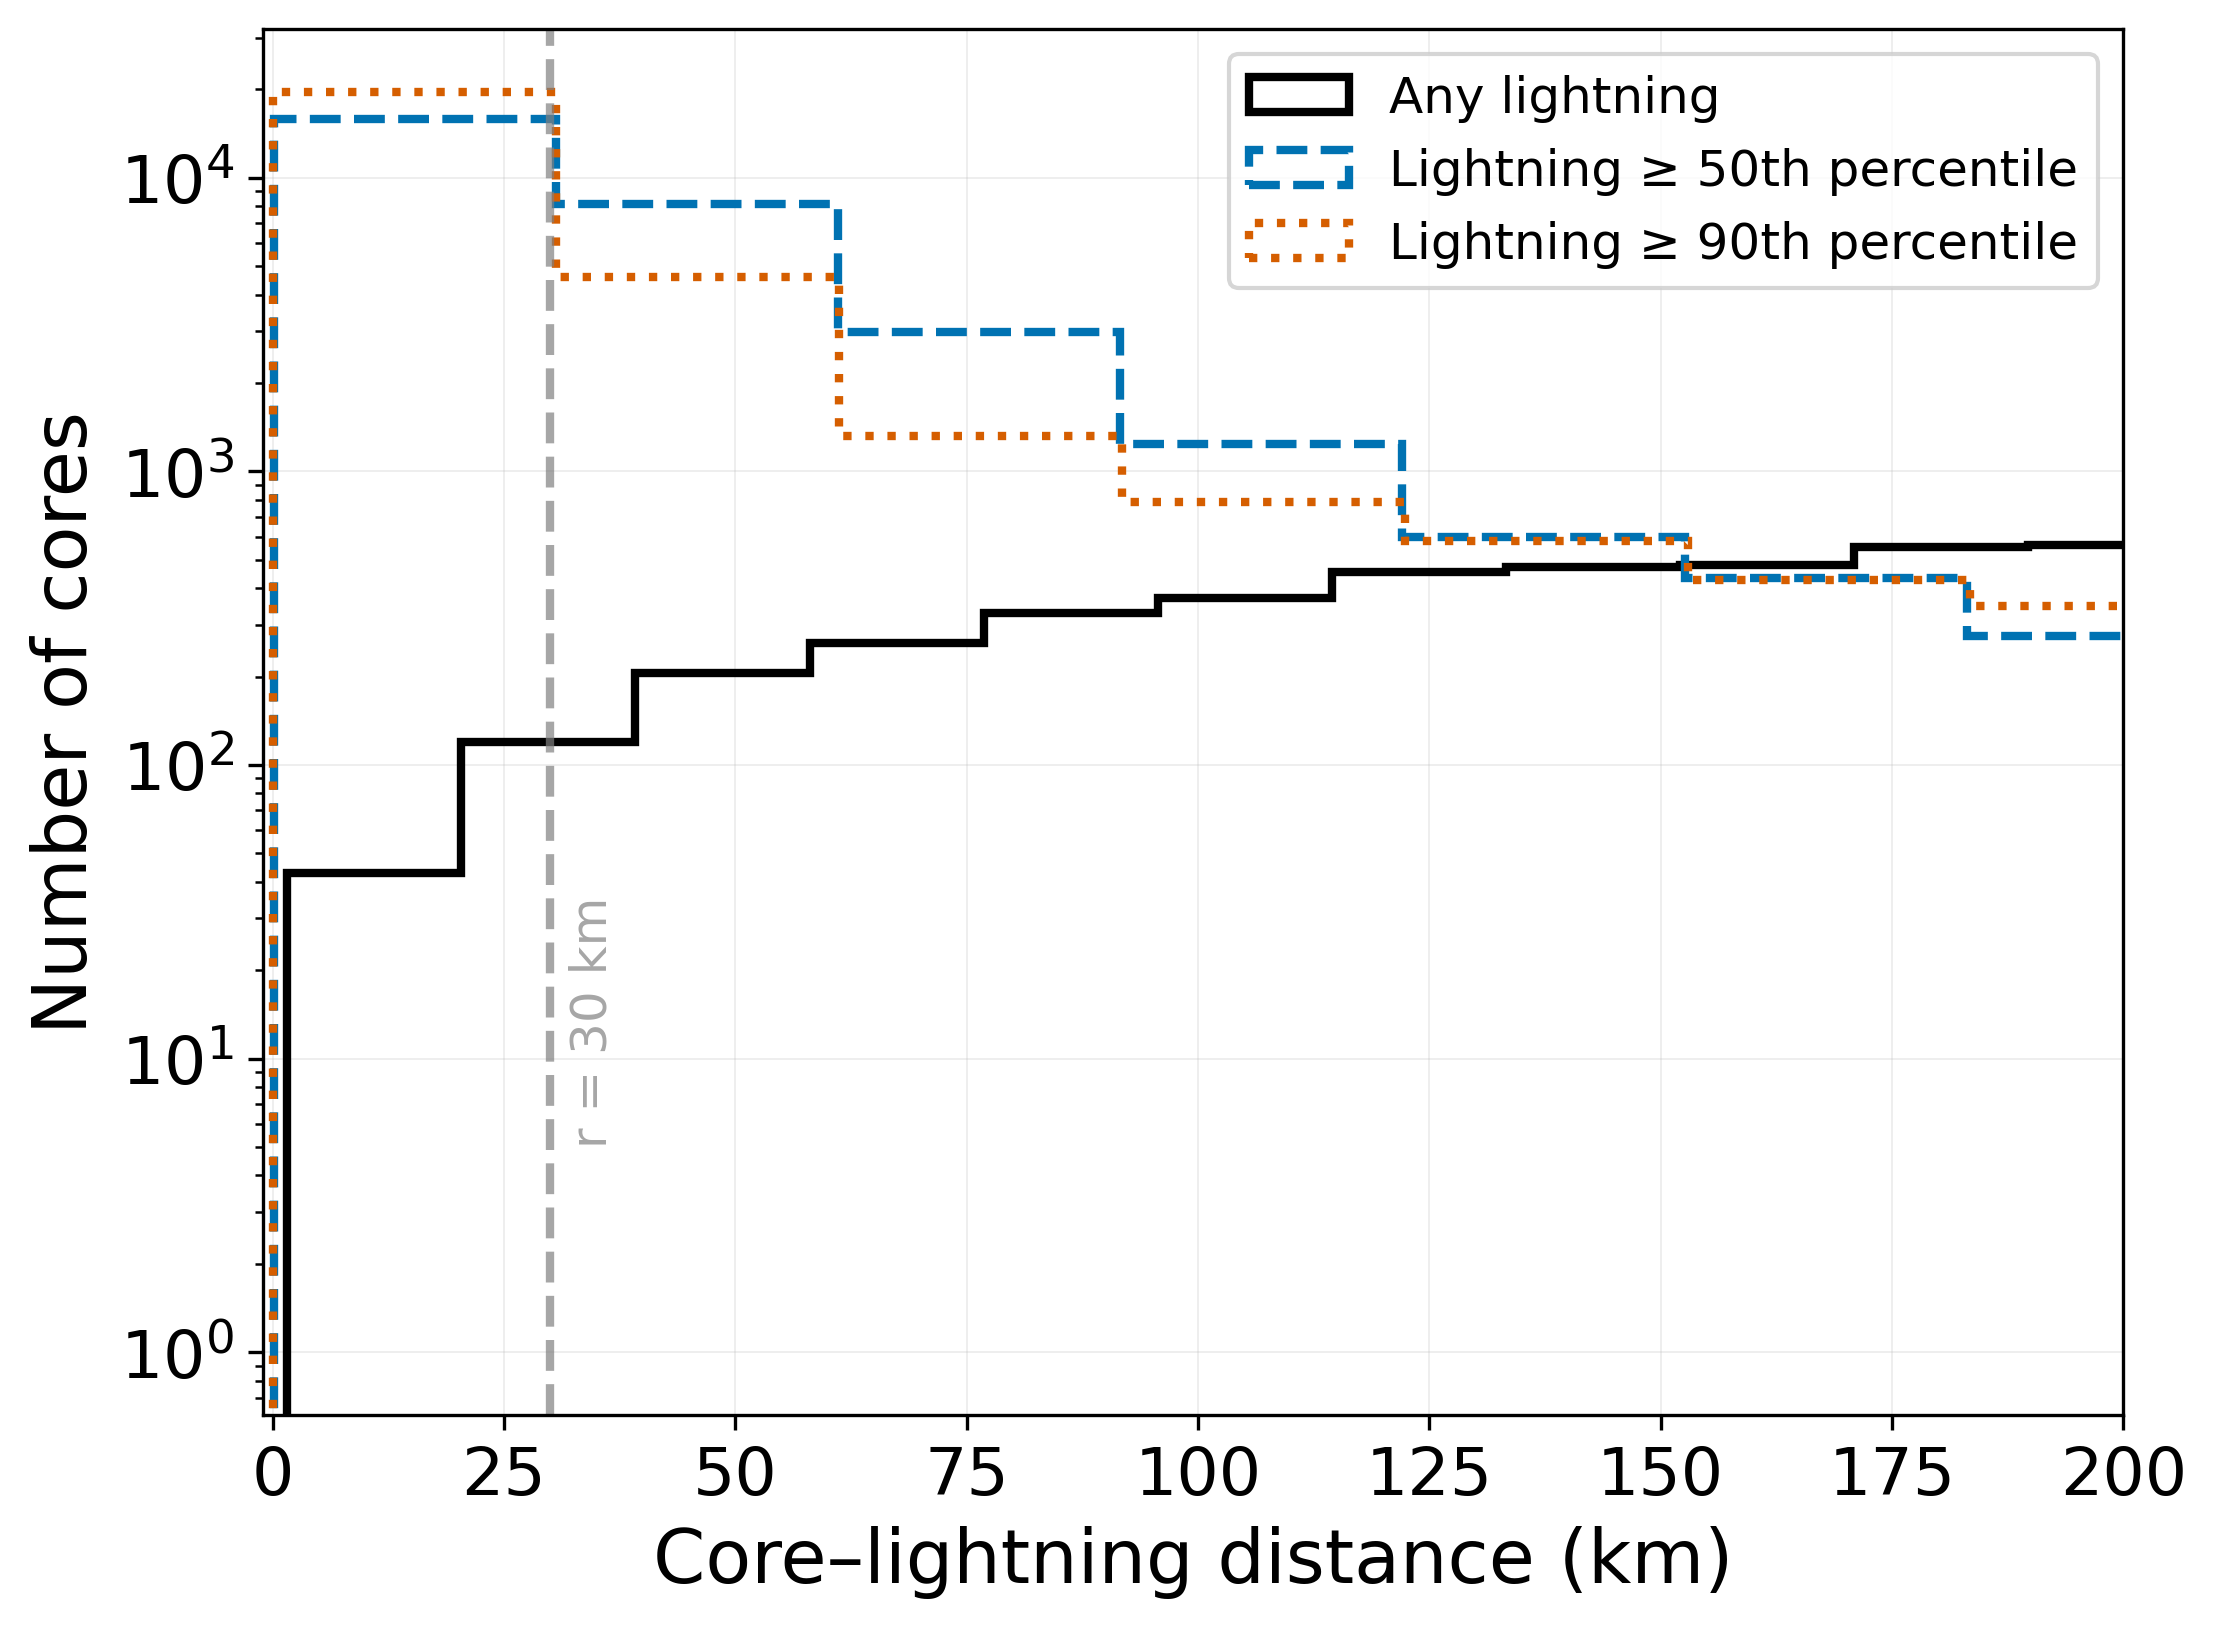

In [9]:
plt.figure(figsize=(8, 6), dpi=300)

labels = {
    0: "Any lightning",
    0.032: "Lightning ≥ 50th percentile",
    1.056: "Lightning ≥ 90th percentile"
}

colors = {
    0: "#000000",     # black
    0.032: "#0072B2", # blue (colorblind-safe)
    1.056: "#D55E00"  # orange-red (colorblind-safe)
}

linestyles = {
    0: "-",
    0.032: "--",
    1.056: ":"
}

for thr, d in distances.items():

    plt.hist(
        d,
        bins=70,
        histtype="step",
        linewidth=2,
        color=colors[thr],
        linestyle=linestyles[thr],
        label=labels[thr]
    )

plt.text(
    32,
    5,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom",
    alpha=0.7
)

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)


plt.yscale("log")

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=12)

plt.xlabel("Core–lightning distance (km)", fontsize=18)

plt.ylabel("Number of cores", fontsize=18)

plt.xlim(-1, 200)

plt.grid(True, linewidth=0.1)

Strong lightning activity is typically colocated with convective cores.

Increasing lightning intensity thresholds progressively concentrates lightning activity near convective cores, indicating that the strongest electrical activity is closely associated with deep convective structures.

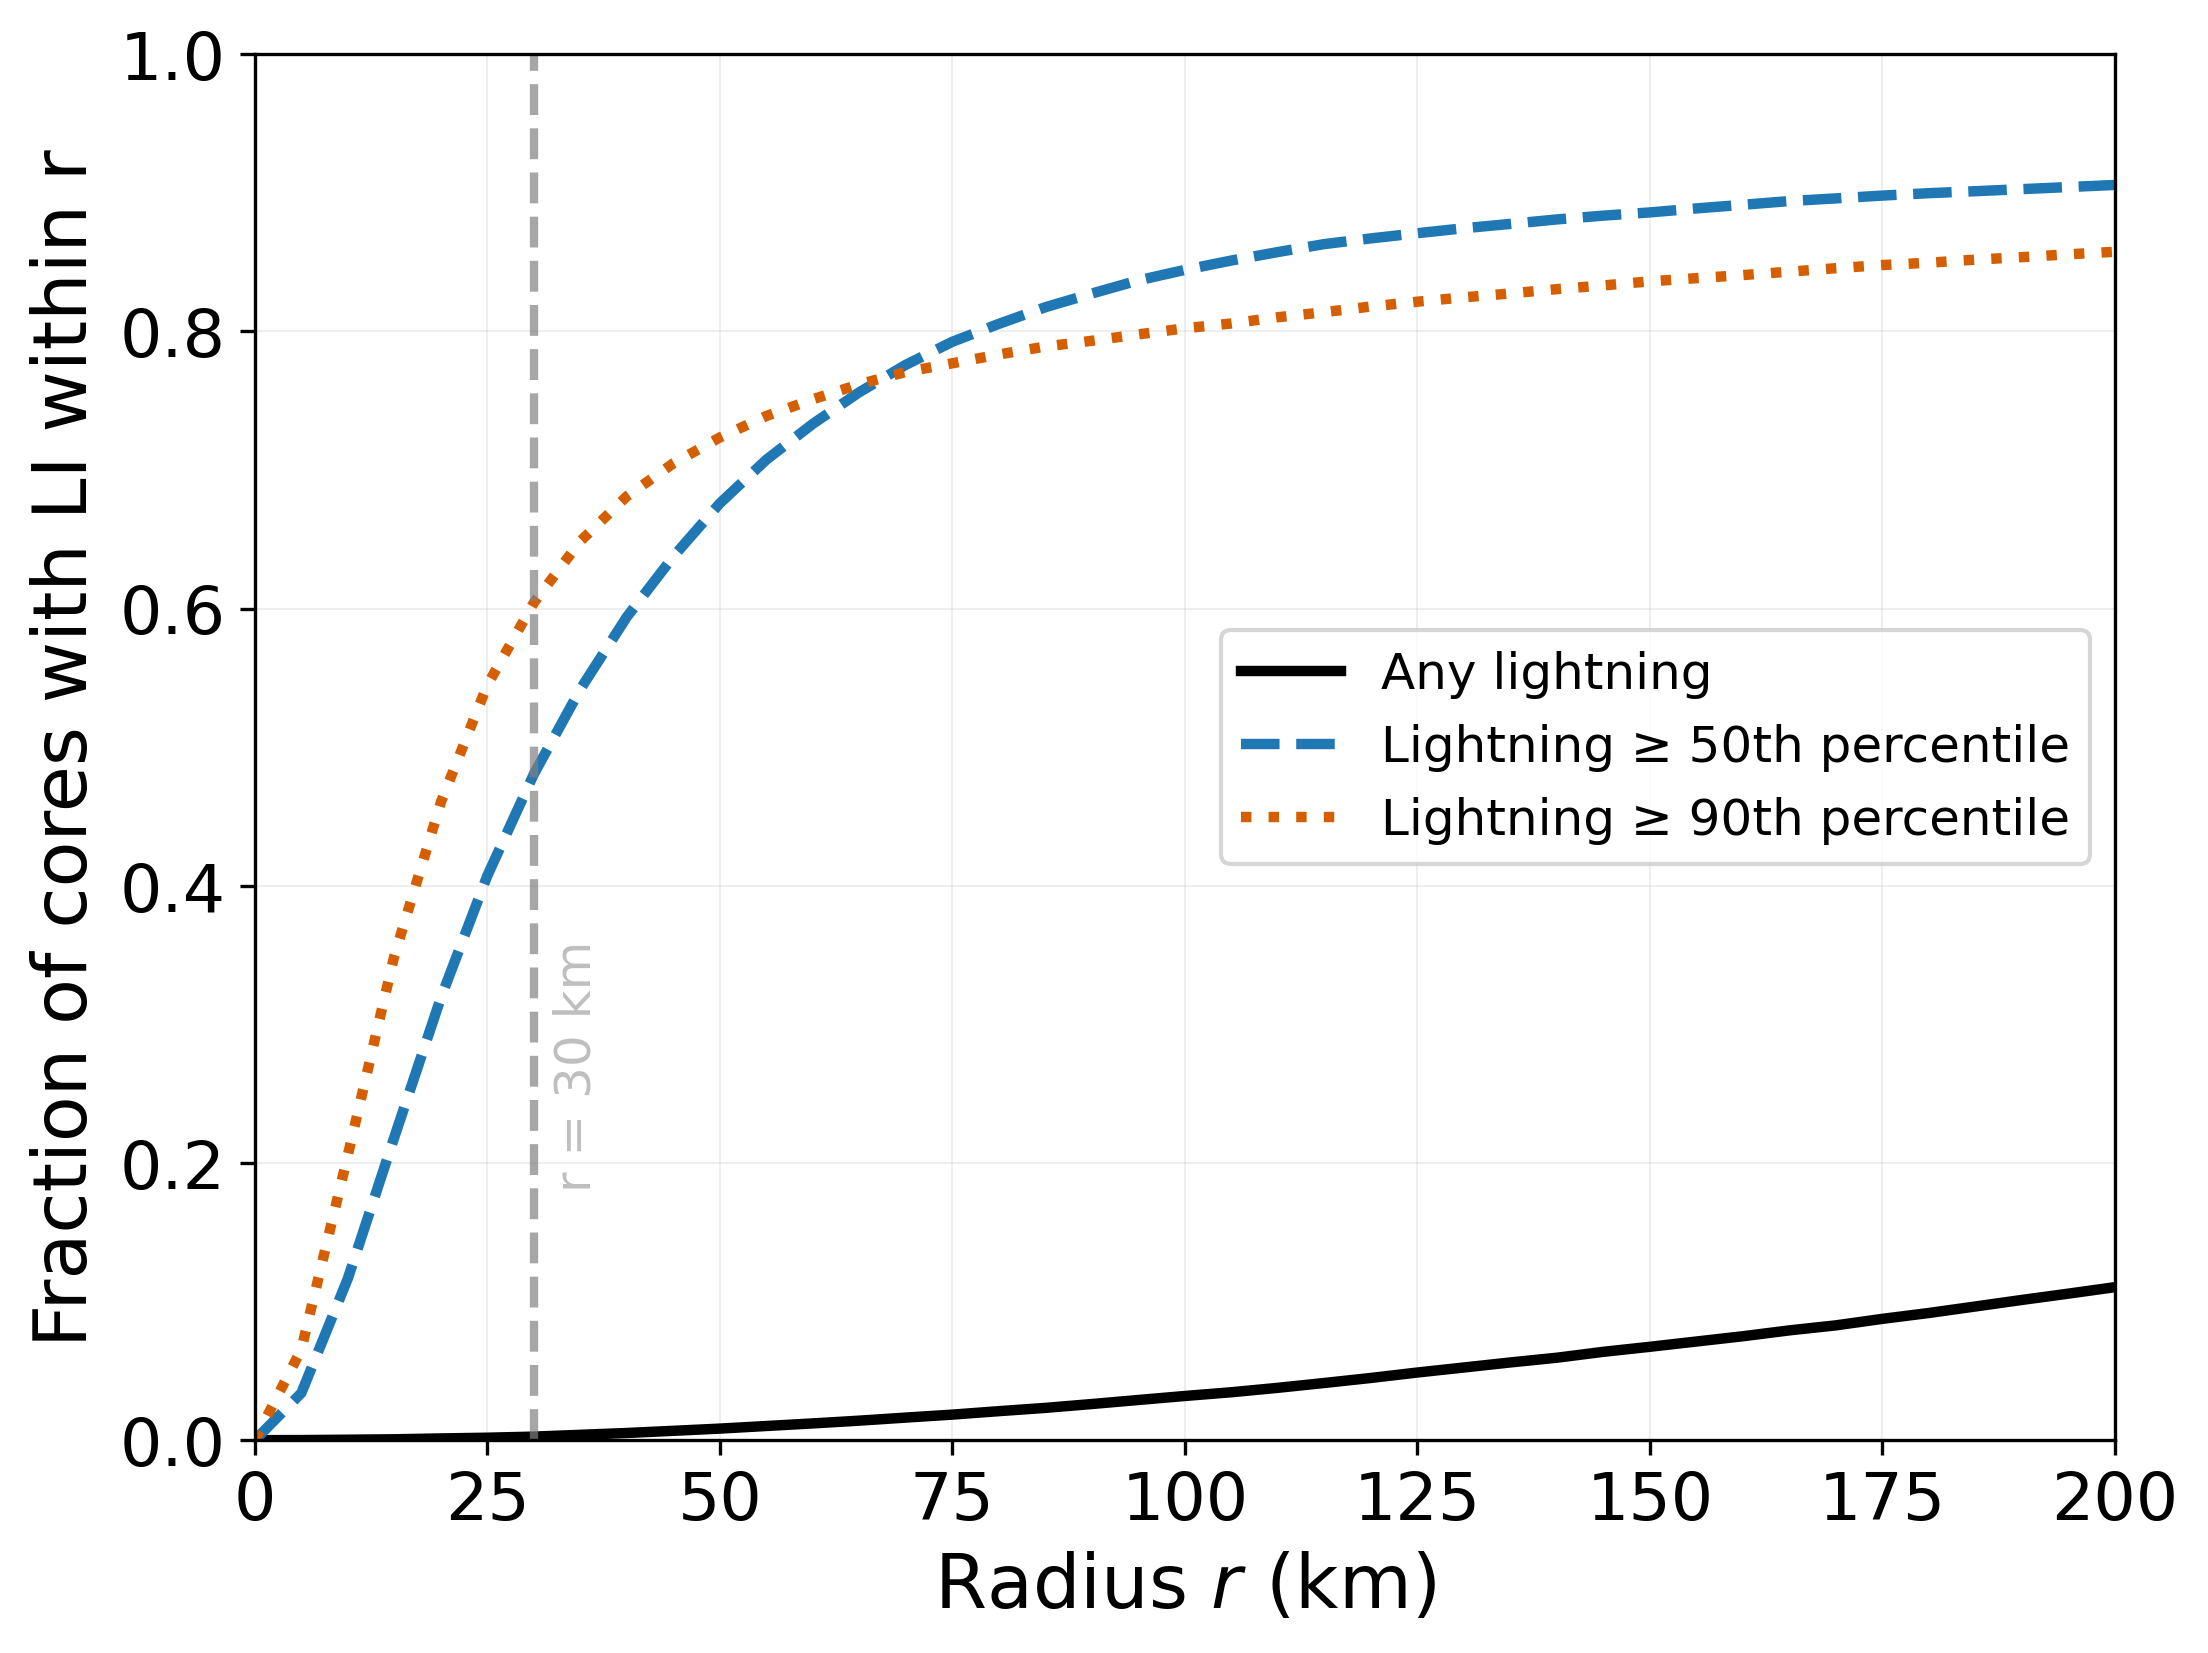

In [8]:
matches_any = distances[0.0]
matches_50  = distances[0.032]
matches_90  = distances[1.056]

radii = np.arange(0, 505, 5)

rates_any = [np.mean(matches_any <= r) for r in radii]
rates_50  = [np.mean(matches_50 <= r) for r in radii]
rates_90  = [np.mean(matches_90 <= r) for r in radii]

plt.figure(figsize=(8, 6), dpi=300)

plt.plot(
    radii,
    rates_any,
    color="black",
    linewidth=2.5,
    label="Any lightning"
)

plt.plot(
    radii,
    rates_50,
    color="#1f77b4",
    linestyle="--",
    linewidth=2.5,
    label="Lightning ≥ 50th percentile"
)

plt.plot(
    radii,
    rates_90,
    color="#d55e00",
    linestyle=":",
    linewidth=2.5,
    label="Lightning ≥ 90th percentile"
)

plt.axvline(
    30,
    color="grey",
    linestyle="--",
    linewidth=2,
    alpha=0.7
)

plt.text(
    32,
    0.18,
    "r = 30 km",
    fontsize=12,
    color="grey",
    rotation=90,
    va="bottom", 
    alpha=0.5
)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=12)

plt.xlabel("Radius $r$ (km)", fontsize=18)
plt.ylabel("Fraction of cores with LI within r", fontsize=18)

plt.xlim(0, 200)
plt.ylim(0, 1)

plt.grid(True, linewidth=0.1)

plt.show()

- Strong lightning is tightly collocated with convective cores.
- Most lightning objects above the 90th percentile occur within roughly 20–40 km of a core.
- Moderate lightning shows slightly broader but still strong coupling.
- Lightning ≥ 50th percentile remains concentrated near cores, with a typical distance scale of ~30 km.

- Weak lightning is spatially diffuse.
- When considering any lightning, the nearest flash to a core is often hundreds of kilometres away, indicating that weak detections are widespread and not necessarily tied to deep convection.

- Lightning intensity controls spatial association with deep convection.
- Increasing the lightning threshold progressively tightens the spatial coupling with convective cores.

- A characteristic coupling scale emerges.
- Around 30–50 km, a large fraction (≈70–80%) of strong lightning events are already associated with convective cores.

- Implication for storm diagnostics.
- Strong lightning activity is a robust indicator of deep convective structures, whereas weak lightning detections alone are a poor proxy for convective cores.
- Increasing the lightning threshold strengthens the spatial coupling with deep convection.